In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Load Data set
file_path = "../Data/Airbnb_Open_Data.csv" 
df = pd.read_csv(file_path)
df.head()

C:\Users\Harsh\AppData\Local\Temp\ipykernel_30204\1410801016.py:3: DtypeWarning: Columns (25: license) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,$74,30.0,270.0,07-05-19,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,$41,10.0,9.0,11/19/2018,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN


In [4]:
# Check column names in the dataset
df.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license'],
      dtype='str')

In [5]:
# No. of Missing values in each column
df.isnull().sum()

id                                     0
NAME                                 250
host id                                0
host_identity_verified               289
host name                            406
neighbourhood group                   29
neighbourhood                         16
lat                                    8
long                                   8
country                              532
country code                         131
instant_bookable                     105
cancellation_policy                   76
room type                              0
Construction year                    214
price                                247
service fee                          273
minimum nights                       409
number of reviews                    183
last review                        15893
reviews per month                  15879
review rate number                   326
calculated host listings count       319
availability 365                     448
house_rules     

In [6]:
# Convert 'last review' to datetime and handle errors
df["last review"] = pd.to_datetime(df["last review"], errors="coerce")

# Fill missing values
df.fillna({"reviews per month": 0, "last review": df["last review"].min()}, inplace=True)

# Drop records with missing 'name' or 'host name'
df.dropna(subset=["NAME", "host name"], inplace=True)

In [7]:
# Remove dollar signs and convert to float
df["price"] = df["price"].replace(r"[\$,]", "", regex=True).astype(float)
df["service fee"] = df["service fee"].replace(r"[\$,]", "", regex=True).astype(float)

In [8]:
# Remove any duplicate Records
df.drop_duplicates(inplace=True)


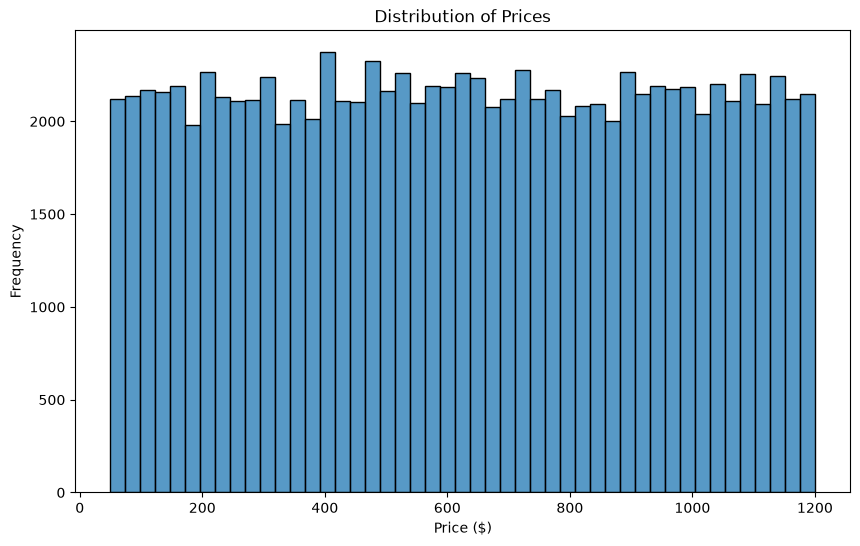

In [9]:
# Chart 1: Distribution of Listing Prices
plt.figure(figsize=(10, 6))
sns.histplot(data=df["price"])
plt.title("Distribution of Prices")
plt.xlabel("Price ($)")
plt.ylabel("Frequency")
plt.savefig("../Images/price_distribution.png", dpi=300)
plt.show()

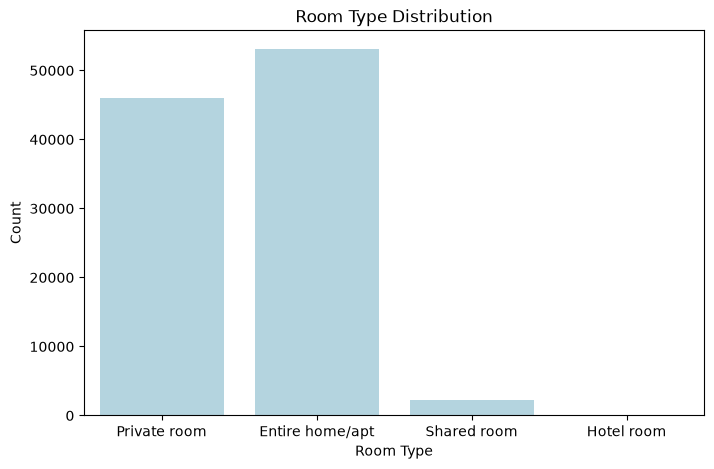

In [10]:
# Chart 2: Room Type Distribution
plt.figure(figsize=(8, 5))
sns.countplot(x=df["room type"], color="lightblue")
plt.title("Room Type Distribution")
plt.xlabel("Room Type")
plt.ylabel("Count")
plt.savefig("../Images/room_type_distribution.png", dpi=300)
plt.show()

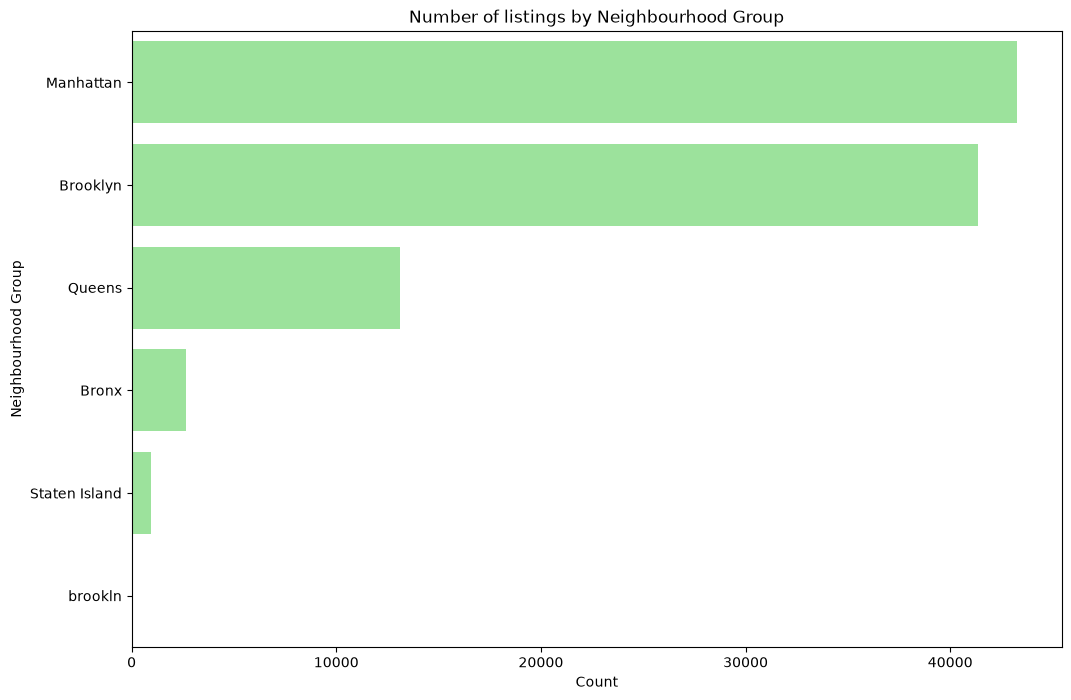

In [11]:
# Chart 3: Neighbourhood Analysis
plt.figure(figsize=(12, 8))
sns.countplot(y=df["neighbourhood group"], color="lightgreen", order=df["neighbourhood group"].value_counts().index)
plt.title("Number of listings by Neighbourhood Group")
plt.xlabel("Count")
plt.ylabel("Neighbourhood Group")
plt.savefig("../Images/room_type_distribution.png", dpi=300)
plt.show()

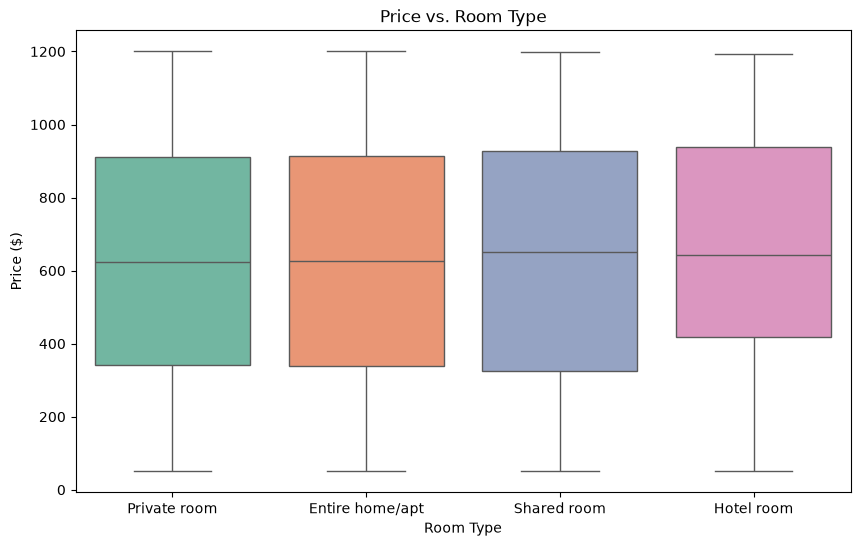

In [ ]:
# Chart 4: Price vs. Room Type
plt.figure(figsize=(10, 6))
sns.boxplot(x="room type", y="price", hue="room type", data=df, palette="Set2")
plt.title("Price vs. Room Type")
plt.xlabel("Room Type")
plt.ylabel("Price ($)")
plt.savefig("../Images/price_vs_room_type.png")
plt.show()

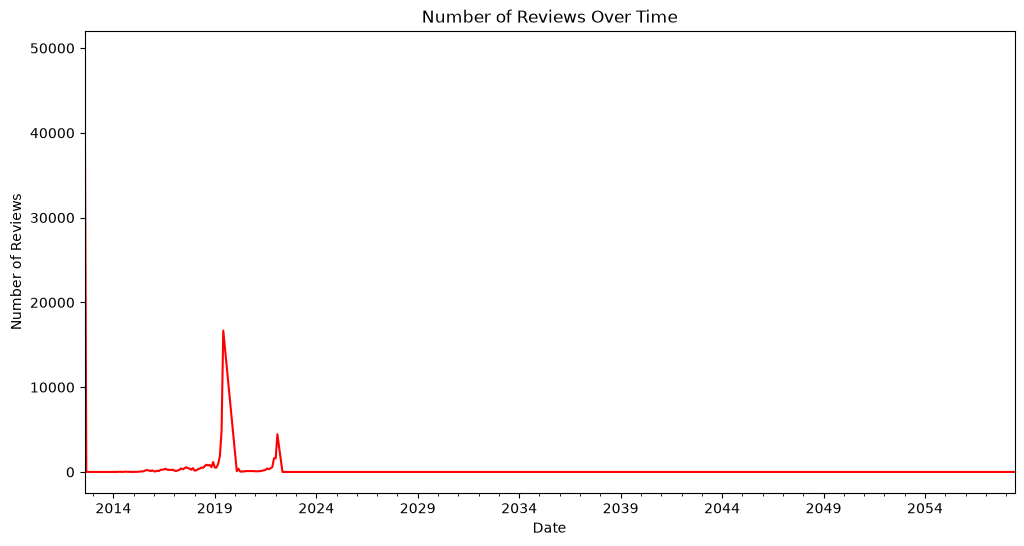

In [44]:
df['last review'] = pd.to_datetime(df['last review'])
reviews_over_time = df.groupby(df['last review'].dt.to_period('M')).size()

plt.figure(figsize=(12, 6))
reviews_over_time.plot(kind='line', color='red')
plt.title('Number of Reviews Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Reviews')
plt.savefig('../Images/reviews_over_time.png')
plt.show()
